In [ ]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error

import ipywidgets as widgets
from ipywidgets import interact


In [2]:
# loading data
X_train_data = pd.read_csv("X_train_processed_61.csv")
y_train_data = pd.read_csv("y_train.csv")

X_train = X_train_data.values
y_train = y_train_data.values.ravel()

In [3]:
import json

In [4]:
with open("column_names.json", "w") as f:
    json.dump(list(X_train_data.columns), f, indent=2)

In [5]:
# starting model:
# healthcare_system_confidence, -government_covid_response, -i11_health
# -perceived_covid_severity, -age, -avoiding_infected_people
# -hand_sanitizer_frequency
# -i12_health_13, -i12_health_22, -i12_health_25

starting_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
    "ord__hand_sanitizer_frequency",
    "ord__i12_health_13",
    "ord__i12_health_22",
    "ord__i12_health_25",
]

In [6]:
# expanded model
# starting model + perceived_infection_risk + employment_status

expanded_cols = starting_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]

In [7]:
# compact model
# starting model - last four variables

compact_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
]

In [24]:
compact_plus_cols = compact_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]


In [27]:
X_train_starting = X_train_data[starting_cols].values
X_train_expanded = X_train_data[expanded_cols].values
X_train_compact = X_train_data[compact_cols].values
X_train_compact_plus = X_train_data[compact_plus_cols].values

In [28]:
feature_sets = {
    "all_61": X_train,
    "starting_model": X_train_starting,
    "expanded_model": X_train_expanded,
    "compact_model": X_train_compact,
    "compact_plus_model": X_train_compact_plus,
}

In [50]:
num_folds = 10
seed = 42
scoring = 'neg_mean_squared_error'

kfold = StratifiedKFold(n_splits=num_folds, random_state=seed, shuffle=True)

model = KNeighborsClassifier()
weighted_model_euclidean = KNeighborsClassifier(weights='distance')
weighted_model_manhattan = KNeighborsClassifier(weights='distance', metric="manhattan")
weighted_model_chebyshev = KNeighborsClassifier(weights='distance', metric="chebyshev")


In [67]:
# different k values list to try
# k_values = [3, 5, 7, 9, 11, 21, 31, 41, 51, 61, 71]
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
param_grid = dict(n_neighbors=k_values)

In [68]:
# k-fold cross validation for each feature set with different models

settings = {
    "uniform":   model,
    "euclidean": weighted_model_euclidean,
    "manhattan": weighted_model_manhattan,
    "chebyshev": weighted_model_chebyshev,
}

rows = []
for name, X_sub in feature_sets.items():
    # scale this model's columns
    rescaledX = StandardScaler().fit_transform(X_sub)

    for setting, estimator in settings.items():
        # try every k with 10-fold CV
        grid = GridSearchCV(estimator=estimator, param_grid=param_grid,
                            scoring=scoring, cv=kfold)
        grid.fit(rescaledX, y_train)

        for k, mean, std in zip(k_values,
                                grid.cv_results_['mean_test_score'],
                                grid.cv_results_['std_test_score']):
            rows.append({"model": name, "setting": setting, "k": k,
                         "cv_mse": -mean, "cv_std": std})

mse_df = pd.DataFrame(rows)
mse_df.head()

,model,setting,k,cv_mse,cv_std
0,all_61,uniform,3,0.232885,0.015438
1,all_61,uniform,5,0.232886,0.012557
2,all_61,uniform,7,0.231532,0.008484
3,all_61,uniform,9,0.230950,0.009664
4,all_61,uniform,11,0.233283,0.010199


In [ ]:
mse_df.to_csv("mse_results.csv", index=False)
mse_df = pd.read_csv("mse_results.csv")

In [ ]:
#import ipywidgets as widgets
#from ipywidgets import interact

In [ ]:


colors = {"all_61": "C0", "starting_model": "C1", "expanded_model": "C2",
          "compact_model": "C3", "compact_plus_model": "C4"}
styles = {"uniform": "-", "euclidean": "--", "manhattan": "-.", "chebyshev": ":"}

def plot_mse(models, settings):
    plt.figure(figsize=(10, 6))
    for name in models:
        for setting in settings:
            d = mse_df[(mse_df["model"] == name) & (mse_df["setting"] == setting)]
            plt.plot(d["k"], d["cv_mse"], styles[setting], marker="o", markersize=3,
                     color=colors[name], label="%s (%s)" % (name, setting))
    plt.xlabel("Number of Neighbors, K")
    plt.ylabel("CV MSE (lower is better)")
    plt.xticks(k_values)
    plt.grid(alpha=0.3)
    if models and settings:
        plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

interact(
    plot_mse,
    models=widgets.ToggleButtons(options=list(colors), description="Model"),
    settings=widgets.ToggleButtons(options=list(styles), description="Setting"),
)

In [ ]:
balacc_scoring = 'balanced_accuracy'

In [66]:
# check for each model (balanced accuracy)

all_cv_balacc = {}
all_stds_balacc = {}
all_params_balacc = {}

euclidean_all_cv_balacc = {}
euclidean_all_stds_balacc = {}
euclidean_all_params_balacc = {}

manhattan_all_cv_balacc = {}
manhattan_all_stds_balacc = {}
manhattan_all_params_balacc = {}

chebyshev_all_cv_balacc = {}
chebyshev_all_stds_balacc = {}
chebyshev_all_params_balacc = {}


for name, X_sub in feature_sets.items():
    # scale this model's columns
    scaler = StandardScaler().fit(X_sub)
    rescaledX = scaler.transform(X_sub)

    # try every k with 10-fold CV
    balacc_grid = GridSearchCV(estimator=model, param_grid=param_grid,
                        scoring=balacc_scoring, cv=kfold)
    balacc_grid_result = balacc_grid.fit(rescaledX, y_train)

    # try every k with weighted model

    euclidean_balacc_grid = GridSearchCV(estimator=weighted_model_euclidean, param_grid=param_grid,
                        scoring=balacc_scoring, cv=kfold)
    euclidean_balacc_grid_result = euclidean_balacc_grid.fit(rescaledX, y_train)

    manhattan_balacc_grid = GridSearchCV(estimator=weighted_model_manhattan, param_grid=param_grid,
                        scoring=balacc_scoring, cv=kfold)
    manhattan_balacc_grid_result = manhattan_balacc_grid.fit(rescaledX, y_train)

    chebyshev_balacc_grid = GridSearchCV(estimator=weighted_model_chebyshev, param_grid=param_grid,
                        scoring=balacc_scoring, cv=kfold)
    chebyshev_balacc_grid_result = chebyshev_balacc_grid.fit(rescaledX, y_train)

    #print("=== %s ===" % name)
    #print("Best: %f using K = %s" % (balacc_grid_result.best_score_, int(balacc_grid_result.best_params_['n_neighbors'])))

    #print("=== weighted %s (Euclidean)===" % name)
    #print("Best: %f using K = %s" % (euclidean_balacc_grid_result.best_score_, int(euclidean_balacc_grid_result.best_params_['n_neighbors'])))

    cv_balacc = balacc_grid_result.cv_results_['mean_test_score']
    cv_stds_balacc = balacc_grid_result.cv_results_['std_test_score']
    cv_params_balacc = balacc_grid_result.cv_results_['params']

    all_cv_balacc[name] = cv_balacc
    all_stds_balacc[name] = cv_stds_balacc
    all_params_balacc[name] = cv_params_balacc

    euclidean_cv_balacc = euclidean_balacc_grid_result.cv_results_['mean_test_score']
    euclidean_cv_stds_balacc = euclidean_balacc_grid_result.cv_results_['std_test_score']
    euclidean_cv_params_balacc = euclidean_balacc_grid_result.cv_results_['params']

    euclidean_all_cv_balacc[name] = euclidean_cv_balacc
    euclidean_all_stds_balacc[name] = euclidean_cv_stds_balacc
    euclidean_all_params_balacc[name] = euclidean_cv_params_balacc

    manhattan_cv_balacc = manhattan_balacc_grid_result.cv_results_['mean_test_score']
    manhattan_cv_stds_balacc = manhattan_balacc_grid_result.cv_results_['std_test_score']
    manhattan_cv_params_balacc = manhattan_balacc_grid_result.cv_results_['params']

    manhattan_all_cv_balacc[name] = manhattan_cv_balacc
    manhattan_all_stds_balacc[name] = manhattan_cv_stds_balacc
    manhattan_all_params_balacc[name] = manhattan_cv_params_balacc

    chebyshev_cv_balacc = chebyshev_balacc_grid_result.cv_results_['mean_test_score']
    chebyshev_cv_stds_balacc = chebyshev_balacc_grid_result.cv_results_['std_test_score']
    chebyshev_cv_params_balacc = chebyshev_balacc_grid_result.cv_results_['params']

    chebyshev_all_cv_balacc[name] = chebyshev_cv_balacc
    chebyshev_all_stds_balacc[name] = chebyshev_cv_stds_balacc
    chebyshev_all_params_balacc[name] = chebyshev_cv_params_balacc

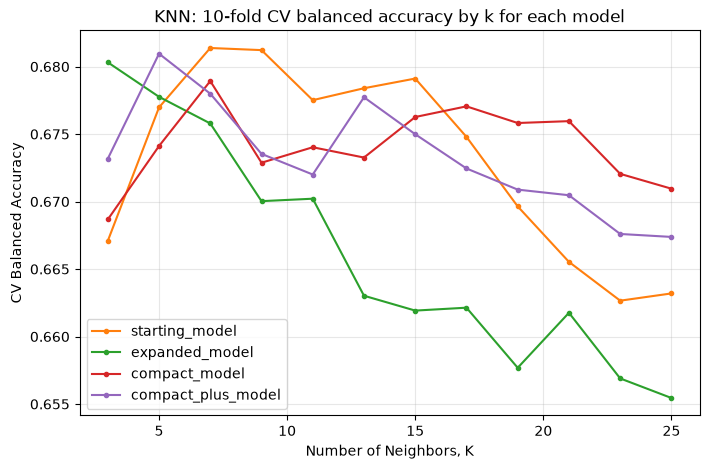

In [43]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3", "compact_plus_model": "C4"}

plt.figure(figsize=(8, 5))
for name, score in all_cv_balacc.items():
    if name == "all_61":
        continue   
    plt.plot(k_values, score, marker='o', markersize=3, label=name, color=colors[name])
plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Balanced Accuracy")
plt.title("KNN: 10-fold CV balanced accuracy by k for each model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

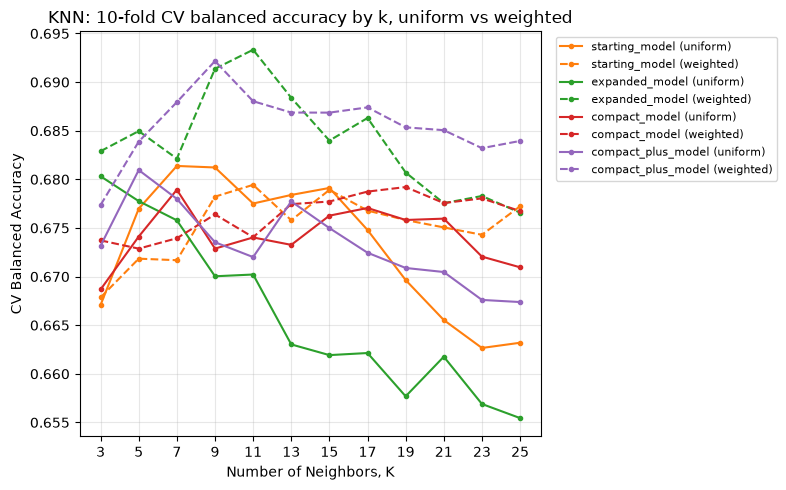

In [63]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3", "compact_plus_model": "C4"}

plt.figure(figsize=(8, 5))
for name, score in w_all_cv_balacc.items():
    if name == "all_61":
        continue   
    plt.plot(k_values, all_cv_balacc[name], "-", marker='o', markersize=3,
             color=colors[name], label=name + " (uniform)")
    plt.plot(k_values, w_all_cv_balacc[name], "--", marker='o', markersize=3,
             color=colors[name], label=name + " (weighted)")

plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Balanced Accuracy")
plt.title("KNN: 10-fold CV balanced accuracy by k, uniform vs weighted")
plt.xticks(k_values)
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()